# Análise do MCTS para PopOut

Neste notebook analisamos o MCTS implementado para o PopOut e as variações
desenvolvidas a partir da versão base. As alterações testadas incidem em
diferentes partes do algoritmo, incluindo as políticas de expansão, simulação e reutilização da árvore. 

Uma das variações substitui a simulação aleatória por uma avaliação com o
algoritmo Minimax. Como o Minimax também foi lecionado nas aulas e é um
algoritmo diferente do Monte Carlo, decidimos  que seria interessante testá-lo separadamente, além de o usar em conjunto com o MCTS.

O objetivo é comparar estas variações em termos de desempenho no jogo e
tempo médio de decisão.

## Estrutura do notebook

1. Metodologia experimental
2. MCTS base (`MCTS`, baseado em estados)
   - Experiência 1: efeito do `child_limit`
   - Experiência 2: efeito do número de iterações
   - Experiência 3: políticas de simulação e reutilização da árvore
3. MCTS novo (`MoveMCTS`, baseado em movimentos)
   - Motivação: eficiência `possible_states` vs `possible_moves`
   - Experiência 4: `MoveMCTS` vs `MCTS` — comparação direta de velocidade
   - Experiência 5: políticas de expansão
4. Minimax com Alpha-Beta Pruning
   - Experiência 6: impacto da heurística (h1 vs h2 vs h3)
   - Experiência 7: impacto da profundidade
5. MCTS híbrido (Minimax como avaliador do rollout)
   - Experiência 8: normalização vs valor direto na retropropagação
6. Comparação geral das melhores configurações
7. Limitações, melhorias futuras e conclusão

## 1. Metodologia experimental

Para comparar os algoritmos, as diferentes variantes são colocadas a jogar
umas contra as outras. Para reduzir o enviesamento causado pela ordem de
jogo, já que o primeiro jogador pode ter vantagem, cada par é testado nas
duas ordens: `A vs B` e `B vs A`.

Para cada variante são recolhidos:

- número de vitórias;
- número de empates;
- número de derrotas;
- `win_rate`, isto é, vitórias / total de jogos;
- `draw_rate`, isto é, empates / total de jogos;
- `loss_rate`, isto é, derrotas / total de jogos;
- `score`, calculado como `(vitórias + 0.5 * empates) / total de jogos`;
- tempo médio por jogada.

O `score` é a métrica principal porque um empate é melhor do que uma derrota,
mas pior do que uma vitória.

Assumimos também a restrição de tempo na realização das experiências. Como
não foi possível correr um número muito elevado de jogos e o MCTS envolve
aleatoriedade nas simulações, os resultados obtidos devem ser analisados
apenas como tendências empíricas, e não como um benchmark definitivo das
variantes testadas.

In [2]:
import sys
import os
sys.path.append(os.path.abspath(".."))

import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from game.game import Game
from game.players import MCTS
from game.mcts_moves import MoveMCTS
from game.minimax import Minimax
from game.utils import (get_all_moves, get_win_or_all, get_win_block_or_all, heuristic_win, heuristic1, heuristic2, heuristic3)

random.seed(42)
np.random.seed(42)

## Funções auxiliares

Nesta secção são definidas funções auxiliares para correr jogos automáticos
entre variantes, recolher estatísticas e apresentar os resultados em tabelas e gráficos.

In [3]:
def variants_stats(variants, n_games=5):
    """
    Corre um torneio todos-contra-todos entre variantes.
    Cada par é testado nas duas ordens (A vs B e B vs A).

    `variants` é uma lista de tuplos (nome, agente).
    O agente pode ser qualquer objeto com um método .move(board, player).
    Se o agente tiver um atributo .root, este é resetado antes de cada jogo
    (necessário para MCTS com save_tree=True).
    """
    stats = {
        name: {"wins": 0, "draws": 0, "losses": 0, "avg_time_sum": 0.0}
        for name, _ in variants
    }

    for i in range(len(variants)):
        for j in range(i + 1, len(variants)):
            for (p1_name, p1_agent), (p2_name, p2_agent) in [
                (variants[i], variants[j]),
                (variants[j], variants[i]),
            ]:
                for _ in range(n_games):
                    # Reset da árvore apenas para agentes MCTS
                    if hasattr(p1_agent, "root"):
                        p1_agent.root = None
                    if hasattr(p2_agent, "root"):
                        p2_agent.root = None

                    result = Game("", "").notebook_run(
                        p1_name, p1_agent.move,
                        p2_name, p2_agent.move,
                    )

                    stats[p1_name]["avg_time_sum"] += result["avg_time_player1"]
                    stats[p2_name]["avg_time_sum"] += result["avg_time_player2"]

                    if result["winner"] == 1:
                        stats[p1_name]["wins"] += 1
                        stats[p2_name]["losses"] += 1
                    elif result["winner"] == -1:
                        stats[p2_name]["wins"] += 1
                        stats[p1_name]["losses"] += 1
                    else:
                        stats[p1_name]["draws"] += 1
                        stats[p2_name]["draws"] += 1

    for name in stats:
        total = stats[name]["wins"] + stats[name]["draws"] + stats[name]["losses"]
        stats[name]["total_games"] = total
        stats[name]["win_rate"]  = stats[name]["wins"]  / total if total else 0
        stats[name]["draw_rate"] = stats[name]["draws"] / total if total else 0
        stats[name]["loss_rate"] = stats[name]["losses"]/ total if total else 0
        stats[name]["score"] = (
            (stats[name]["wins"] + 0.5 * stats[name]["draws"]) / total
            if total else 0
        )
        stats[name]["avg_time_per_move"] = (
            stats[name]["avg_time_sum"] / total if total else 0
        )

    return stats


def stats_dataframe(stats):
    """Converte o dicionário de stats num DataFrame ordenado por score."""
    df = pd.DataFrame.from_dict(stats, orient="index")
    cols = ["wins", "draws", "losses", "total_games",
            "win_rate", "draw_rate", "loss_rate", "score", "avg_time_per_move"]
    return df[cols].sort_values(["score", "avg_time_per_move"], ascending=[False, True])


def plot_bars(stats, title):
    """Gráfico de barras agrupadas: vitórias, empates, derrotas por variante."""
    variants = list(stats.keys())
    measurements = [
        ("Wins",   [stats[v]["wins"]   for v in variants], "#2ca02c"),
        ("Draws",  [stats[v]["draws"]  for v in variants], "#ff7f0e"),
        ("Losses", [stats[v]["losses"] for v in variants], "#d62728"),
    ]
    x = np.arange(len(variants))
    width = 0.22
    fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
    for idx, (label, values, color) in enumerate(measurements):
        rects = ax.bar(x + width * idx, values, width, label=label, color=color)
        ax.bar_label(rects, padding=3)
    ax.set_ylabel("Número de jogos")
    ax.set_title(title)
    ax.set_xticks(x + width, variants, rotation=35, ha="right")
    ax.legend(loc="upper right", ncols=3)
    plt.show()


def plot_score_vs_time(stats, title):
    """Scatter plot: score vs tempo médio por jogada."""
    names  = list(stats.keys())
    times  = [stats[n]["avg_time_per_move"] for n in names]
    scores = [stats[n]["score"]             for n in names]
    plt.figure(figsize=(6, 4))
    plt.scatter(times, scores)
    for name, x, y in zip(names, times, scores):
        plt.annotate(name, (x, y), textcoords="offset points", xytext=(5, 5))
    plt.xlabel("Tempo médio por jogada (s)")
    plt.ylabel("Score")
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.show()

---
## 2. MCTS base — classe `MCTS` (baseado em estados)

A primeira implementação de MCTS usa a classe Node, onde cada nó guarda o estado atual, o jogador seguinte, os filhos já criados e as estatísticas usadas pelo UCT. Além disso, mantém uma lista de estados possíveis ainda por expandir.

Durante a expansão, um desses estados é retirado dessa lista e usado para criar um novo nó filho. Na simulação, a implementação continua a trabalhar diretamente com estados: em cada passo são gerados os estados seguintes possíveis e é escolhido um deles.

Como esta versão trabalha com listas de estados possíveis, em vez de guardar diretamente os movimentos disponíveis, torna-se menos eficiente. Para escolher a jogada final, é necessário usar infer_move_by_diff, comparando o estado da raiz com o estado do melhor filho. Esta abordagem motiva a versão que iremos apresentar mais tarde, baseada diretamente em movimentos.

A implementação segue as quatro etapas do algoritmo:

1. **Selecção**: percorre a árvore escolhendo filhos com maior valor UCT.  
2. **Expansão**: quando existe um filho ainda não explorado, esse estado é adicionado à árvore.  
3. **Simulação**: a partir do novo estado, é jogada uma partida aleatória até um estado terminal.  
4. **Retropropagação**: o resultado da simulação é propagado até à raiz, actualizando visitas e vitórias.

A fórmula UCT usada é:

$$
UCT = \frac{Wins}{Visits} + c  \sqrt{\frac{\log(Parent\_Visits)}{Visits}}
$$

com $c = \sqrt{2}$ por defeito, como sugerido por Norvig no livro usado como bibliografia obrigatória da cadeira. Como tal, decidimos manter este valor e testar alterações que nos pareciam mais interessantes para o problema.

### Experiência 1 — Efeito do `child_limit`

Compara o MCTS sem limite de filhos(no máximo 14) com variantes que consideram apenas 2, 4 ou 8 filhos por nó.

**Hipótese**: limitar o número de filhos reduz o espaço de pesquisa por iteração, mas também pode excluir jogadas importantes porque a selecção dos filhos é **aleatória**.

Todos as variações usam 300 iterações, garantindo que a diferença entre os resultados se deve sobretudo ao valor de child_limit e não ao número de simulações realizadas.

In [7]:
child_variants = [
    ("all_300", MCTS(max_iter=300)),
    ("child_2_300", MCTS(child_limit=2, max_iter=300)),
    ("child_4_300", MCTS(child_limit=4, max_iter=300)),
    ("child_8_300", MCTS(child_limit=8, max_iter=300)),
]

stats_children = variants_stats(child_variants, n_games=10)
stats_dataframe(stats_children)

,wins,draws,losses,total_games,win_rate,draw_rate,loss_rate,score,avg_time_per_move
all_300,51,0,9,60,0.850000,0.0,0.150000,0.850000,0.312889
child_8_300,43,0,17,60,0.716667,0.0,0.283333,0.716667,0.309130
child_4_300,20,0,40,60,0.333333,0.0,0.666667,0.333333,0.300323
child_2_300,6,0,54,60,0.100000,0.0,0.900000,0.100000,0.282186


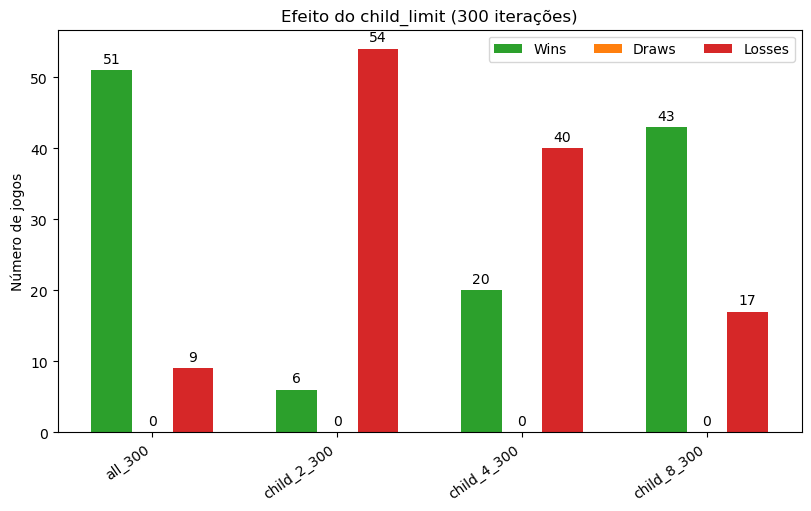

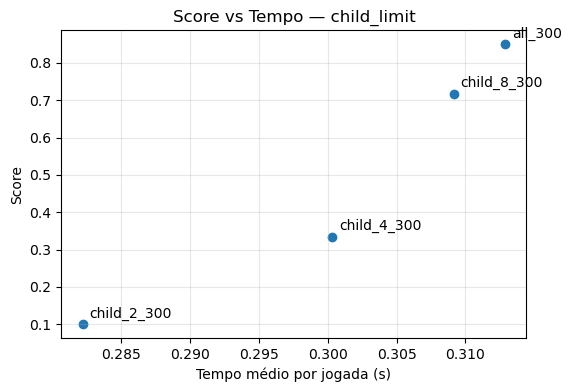

In [8]:
plot_bars(stats_children, "Efeito do child_limit (300 iterações)")
plot_score_vs_time(stats_children, "Score vs Tempo — child_limit")

#### Discussão dos resultados

Limitar o número de filhos para valores muito baixos prejudica claramente a qualidade do algoritmo. O `child_2_300` obtém apenas 6 vitórias e o `child_4_300` regista 20 vitórias, mostrando que a seleção aleatória de poucos estados pode excluir jogadas importantes.

Com `child_limit=8`, os resultados melhoram bastante, chegando a 43 vitórias. Ainda assim, esta variante continua abaixo do MCTS sem limite, `all_300`, que obtém o melhor resultado com 51 vitórias.

Em termos de tempo médio por jogada, as diferenças entre as variantes são reduzidas. Assim, para 300 iterações, limitar demasiado o número de filhos não compensa a perda de desempenho. Neste teste, a variante all_300 apresenta o melhor resultado global.

### Experiência 2 — Efeito do número de iterações

Compara a variante `all` do MCTS com diferentes números de iterações: 50, 100, 300, 500 e 1000.

**Hipótese**: aumentar o número de iterações deve melhorar a qualidade das decisões, porque o algoritmo realiza mais simulações e atualiza melhor as estimativas usadas pelo UCT. No entanto, esse ganho pode não ser linear e implica um aumento do tempo médio por jogada.

In [28]:
iteration_variants = [
    ("all_50", MCTS(max_iter=50)),
    ("all_100", MCTS(max_iter=100)),
    ("all_300", MCTS(max_iter=300)),
    ("all_500", MCTS(max_iter=500)),
    ("all_1000", MCTS(max_iter=1000)),
]

stats_iter = variants_stats(iteration_variants, n_games=10)
stats_dataframe(stats_iter)

,wins,draws,losses,total_games,win_rate,draw_rate,loss_rate,score,avg_time_per_move
all_1000,66,0,14,80,0.8250,0.0,0.1750,0.8250,0.995806
all_500,63,0,17,80,0.7875,0.0,0.2125,0.7875,0.524794
all_300,43,0,37,80,0.5375,0.0,0.4625,0.5375,0.330374
all_100,18,0,62,80,0.2250,0.0,0.7750,0.2250,0.123093
all_50,10,0,70,80,0.1250,0.0,0.8750,0.1250,0.064549


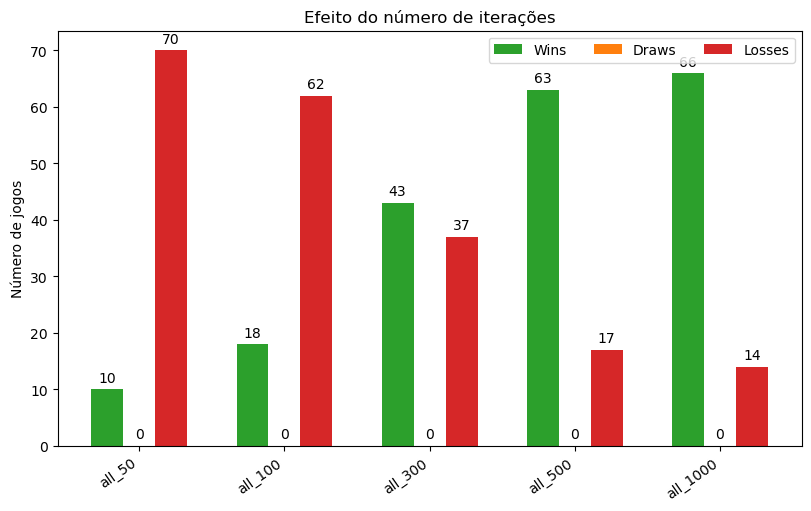

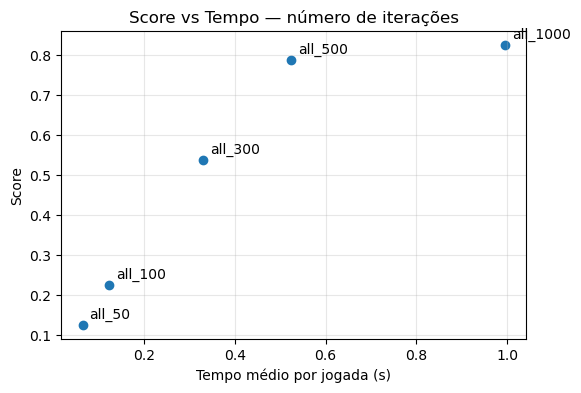

In [29]:
plot_bars(stats_iter, "Efeito do número de iterações")
plot_score_vs_time(stats_iter, "Score vs Tempo — número de iterações")

#### Conclusão

Os resultados mostram que o aumento do número de iterações melhora claramente o desempenho da variante `all`. A taxa de vitória sobe de 12,5% com `all_50` para 82,5% com `all_1000`, indicando que mais simulações permitem obter estimativas mais fiáveis para a escolha das jogadas.

No entanto, esta melhoria tem um custo direto no tempo médio por jogada. O tempo aumenta de cerca de 0.06 segundos em `all_50` para cerca de 1 segundo em `all_1000`.

Assim, existe um compromisso entre qualidade e tempo de resposta. Neste teste, `all_500` já apresenta um desempenho bastante elevado, com 78,75% de vitórias, mantendo um tempo médio de cerca de 0.52s por jogada, quase metade do tempo de `all_1000`, que demora cerca de 1s.

### Experiência 3 — Heurísticas de simulação e reutilização da árvore

Compara variantes que alteram a **política de simulação** ou reutilizam informação entre jogadas.

| Variante | Descrição |
|---|---|
| `base` | Simulação puramente aleatória |
| `win` | Durante a simulação, se existir uma jogada vencedora imediata, é escolhida |
| `tree` | A árvore é reutilizada entre jogadas (`save_tree=True`) |
| `win_tree` | Combina heurística de vitória com reutilização da árvore |
| `block` | Evita jogadas que permitem vitória imediata ao adversário (mais lento) |
| `full` | `win` + `block` + `tree` |

**Nota sobre `block`**: esta estratégia avalia as respostas possíveis do adversário para cada jogada simulada, o que aumenta muito o custo por iteração. É testada com menos iterações para manter tempos comparáveis.

In [11]:
# Variantes leves — 300 iterações
heuristic_light = [
    ("base_300",     MCTS(max_iter=300)),
    ("win_300",      MCTS(max_iter=300, heuristic_win=True)),
    ("tree_300",     MCTS(max_iter=300, save_tree=True)),
    ("win_tree_300", MCTS(max_iter=300, heuristic_win=True, save_tree=True)),
]

stats_heuristic = variants_stats(heuristic_light, n_games=10)
stats_dataframe(stats_heuristic)

,wins,draws,losses,total_games,win_rate,draw_rate,loss_rate,score,avg_time_per_move
win_tree_300,42,0,18,60,0.700000,0.0,0.300000,0.700000,0.168381
win_300,38,0,22,60,0.633333,0.0,0.366667,0.633333,0.167277
tree_300,22,0,38,60,0.366667,0.0,0.633333,0.366667,0.293654
base_300,18,0,42,60,0.300000,0.0,0.700000,0.300000,0.309039


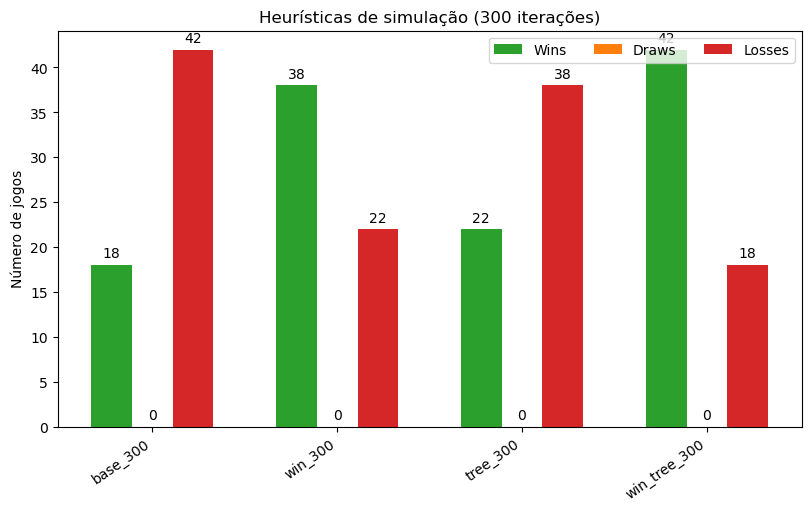

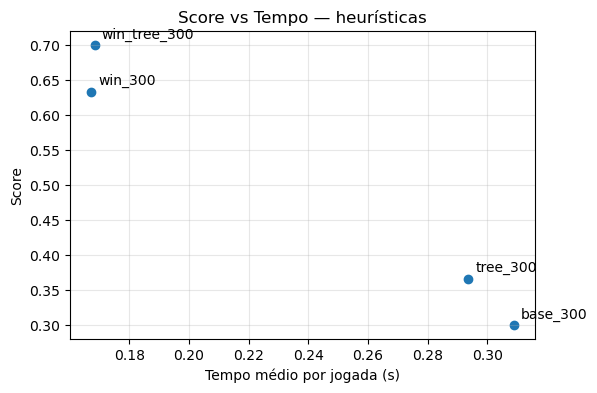

In [12]:
plot_bars(stats_heuristic, "Heurísticas de simulação (300 iterações)")
plot_score_vs_time(stats_heuristic, "Score vs Tempo — heurísticas")

In [14]:
# Teste complementar incluindo block — 100 iterações (block é muito mais lento)
heuristic_with_block = [
    ("base_100",      MCTS(max_iter=100)),
    ("block_100",     MCTS(max_iter=100, heuristic_block_win=True)),
]

stats_block = variants_stats(heuristic_with_block, n_games=5)
stats_dataframe(stats_block)

,wins,draws,losses,total_games,win_rate,draw_rate,loss_rate,score,avg_time_per_move
base_100,5,0,5,10,0.5,0.0,0.5,0.5,0.123170
block_100,5,0,5,10,0.5,0.0,0.5,0.5,3.496366


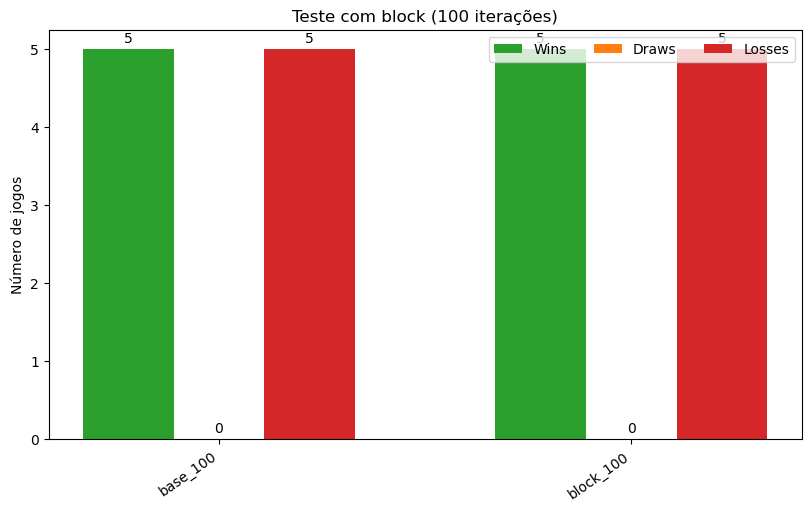

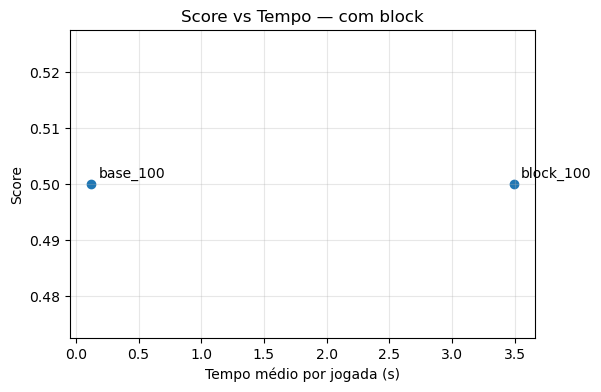

In [15]:
plot_bars(stats_block, "Teste com block (100 iterações)")
plot_score_vs_time(stats_block, "Score vs Tempo — com block")

#### Discussão dos resultados

Os resultados mostram que a heurística `win` melhora o desempenho da variante base. A versão `win_300` obtém 38 vitórias, contra 18 da `base_300`. Isto indica que escolher uma jogada vencedora durante a simulação permite estimar melhor o verdadeiro valor dos estados, em vez de depender apenas de rollouts totalmente aleatórios.

A reutilização da árvore com `save_tree` também tem impacto positivo. A variante `win_tree_300` obtém o melhor resultado, com 42 vitórias, mostrando que preservar a informação já acumulada entre jogadas torna a pesquisa mais eficaz. Embora esta conclusão não seja 100% garantida, devido à componente aleatória das simulações.

A heurística `block` foi testada separadamente com apenas 100 iterações, porque tem um custo computacional muito elevado. Mesmo com este número reduzido de iterações, o tempo médio por jogada sobe de cerca de 0.12 segundos em `base_100` para cerca de 3.50 segundos em `block_100`, sem melhoria no resultado, já que ambas as variantes obtêm 5 vitórias e 5 derrotas.

Assim, `block` não compensa nesta implementação: aumenta muito o tempo de execução e não apresenta ganho evidente nos resultados. A melhor combinação neste conjunto de testes é `win_tree_300`, que junta a heurística `win` com a reutilização da árvore.

---
## 3. MCTS novo — classe `MoveMCTS` (baseado em movimentos)

#### `possible_states` vs `possible_moves`

A classe `MCTS` original usa `possible_states`, que gera diretamente os estados possíveis seguintes. Como cada estado filho corresponde a uma cópia completa do tabuleiro depois de uma jogada, isto torna-se pesado: em PopOut, cada estado pode ter até 14 movimentos possíveis (7 `drops` + 7 `pops`) e, durante a simulação, este processo repete-se a cada passo até ao fim do rollout.

A classe `MoveMCTS` passa a usar `possible_moves`, que devolve apenas uma lista de tuplos `(tipo, coluna)`, sem criar imediatamente os tabuleiros resultantes. Desta forma, a lista de filhos por expandir passa a guardar movimentos e não estados completos. O tabuleiro só é copiado quando é necessário criar um novo nó na árvore.

Durante a simulação, também é criada apenas uma cópia inicial do estado do nó, sobre a qual os movimentos escolhidos são aplicados diretamente. Assim, a criação de cópias do tabuleiro é drasticamente reduzida em comparação com a versão baseada em `possible_states`. Ainda são feitas cópias adicionais quando são usadas regras de simulação como `heuristic_win` e `heuristic_block_win`, porque estas precisam de testar consequências de movimentos antes de escolher a jogada.

Adicionalmente, a nova implementação guarda o **movimento que gerou cada nó** (`causal_move`), eliminando a necessidade da função `infer_move_by_diff`, que inferia a jogada por diferença de alturas.

Apesar destas alterações, a estrutura base do MCTS mantém-se: seleção com UCT, expansão, simulação e retropropagação. A principal diferença está na representação usada durante a pesquisa, que passa de estados completos para movimentos.


### Experiência 4 — `MoveMCTS` vs `MCTS`: comparação direta

O objetivo aqui é confirmar empiricamente que o `MoveMCTS` é mais rápido por jogada do que o `MCTS` equivalente e verificar se a qualidade se mantém.

Comparamos configurações equivalentes: mesmas iterações, sem heurísticas extra, sem `save_tree`.

In [30]:
efficiency_variants = [
    ("MCTS_estados_300",     MCTS(max_iter=300)),
    ("MoveMCTS_movimentos_300", MoveMCTS(max_iter=300)),
]

# n_games=20 para ter uma amostra maior — o objetivo principal é medir tempo
stats_efficiency = variants_stats(efficiency_variants, n_games=20)
stats_dataframe(stats_efficiency)

,wins,draws,losses,total_games,win_rate,draw_rate,loss_rate,score,avg_time_per_move
MCTS_estados_300,22,0,18,40,0.55,0.0,0.45,0.55,0.312100
MoveMCTS_movimentos_300,18,0,22,40,0.45,0.0,0.55,0.45,0.046724


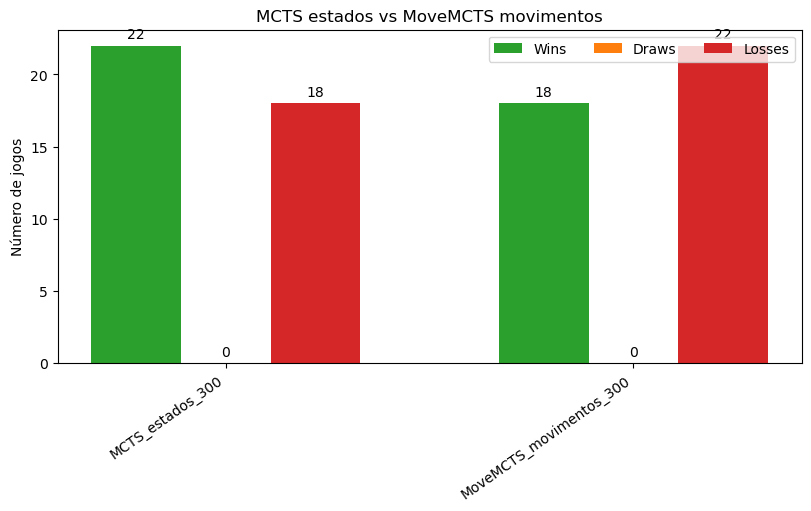

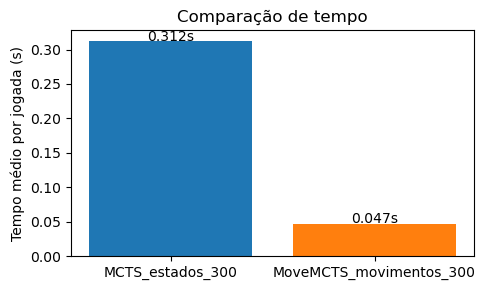

In [31]:
plot_bars(stats_efficiency, "MCTS estados vs MoveMCTS movimentos")

# Comparação directa de tempo médio por jogada
names = list(stats_efficiency.keys())
times = [stats_efficiency[n]["avg_time_per_move"] for n in names]
plt.figure(figsize=(5, 3))
plt.bar(names, times, color=["#1f77b4", "#ff7f0e"])
plt.ylabel("Tempo médio por jogada (s)")
plt.title("Comparação de tempo")
for i, (n, t) in enumerate(zip(names, times)):
    plt.text(i, t + 0.001, f"{t:.3f}s", ha="center")
plt.tight_layout()
plt.show()

#### Discussão dos resultados

Os resultados mostram que o `MoveMCTS` é bastante mais eficiente do que o `MCTS` original baseado em estados. O tempo médio por jogada desce de cerca de 0.31s em `MCTS_estados_300` para cerca de 0.05s em `MoveMCTS_movimentos_300`, tornando a execução aproximadamente 6 a 7 vezes mais rápida.

Em termos de vitórias, o `MCTS_estados_300` obteve 22 vitórias e o `MoveMCTS_movimentos_300` obteve 18. No entanto, esta diferença é pequena e pode estar associada à aleatoriedade das simulações, uma vez que a lógica principal de decisão do algoritmo se mantém a mesma.

Como o `MCTS` original baseado em `possible_states` é demasiado ineficiente, as próximas alterações serão aplicadas apenas ao `MoveMCTS`.

> **A partir daqui, todas as experiências usarão a nova arquitetura `MoveMCTS`.**

### Experiência 5 — Políticas de expansão

As estratégias de expansão determinam **que movimentos são candidatos a expansão** em cada nó. Ao contrário do `child_limit` (que limita aleatoriamente), estas estratégias usam **conhecimento do domínio**:

- `get_all_moves` -> Expande todos os movimentos válidos (comportamento base);
- `get_win_or_all` -> Se existir uma jogada vencedora imediata, expande **só essa**; caso contrário, expande todas;
- `get_win_block_or_all` -> Prioriza jogadas vencedoras; se não houver, evita movimentos que permitem vitória imediata ao adversário; caso contrário, expande todas.

A intuição é que restringir a expansão a movimentos relevantes concentra o orçamento de iterações em partes da árvore que realmente importam.

Esta abordagem é preferível a aplicar verificações pesadas diretamente em todos os passos da simulação, porque o filtro é usado apenas na fase de expansão dos nós. Assim, tenta-se orientar a árvore para movimentos mais promissores sem aumentar tanto o custo dos rollouts.

Usamos 1000 iterações porque, nesta fase, o `MoveMCTS` já apresenta um tempo por jogada bastante inferior ao da implementação original. Isto permite aumentar o número de simulações sem tornar o tempo de resposta demasiado elevado, obtendo uma melhor relação entre desempenho e custo computacional.


In [18]:
expansion_variants = [
    ("all_1000",          MoveMCTS(max_iter=1000, expansion_policy=get_all_moves)),
    ("win_or_all_1000",   MoveMCTS(max_iter=1000, expansion_policy=get_win_or_all)),
    ("win_block_1000",    MoveMCTS(max_iter=1000, expansion_policy=get_win_block_or_all)),
]

stats_expansion = variants_stats(expansion_variants, n_games=10)
stats_dataframe(stats_expansion)

,wins,draws,losses,total_games,win_rate,draw_rate,loss_rate,score,avg_time_per_move
win_or_all_1000,27,0,13,40,0.675,0.0,0.325,0.675,0.136920
win_block_1000,20,0,20,40,0.500,0.0,0.500,0.500,0.243223
all_1000,13,0,27,40,0.325,0.0,0.675,0.325,0.139495


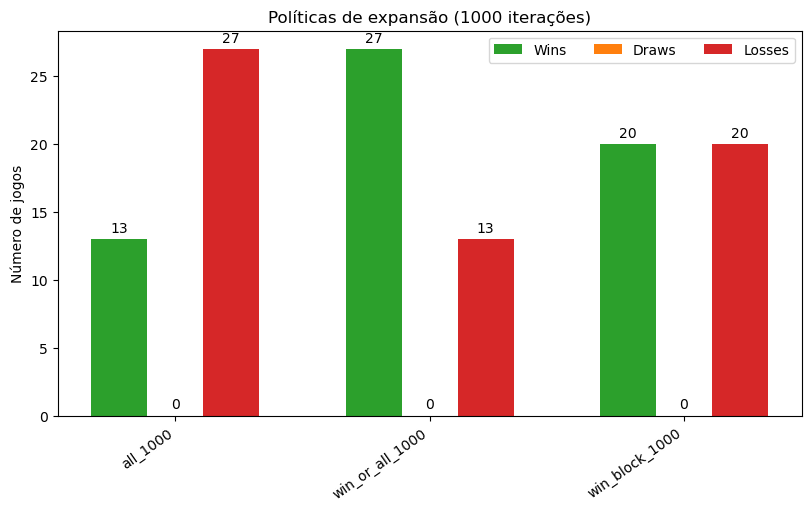

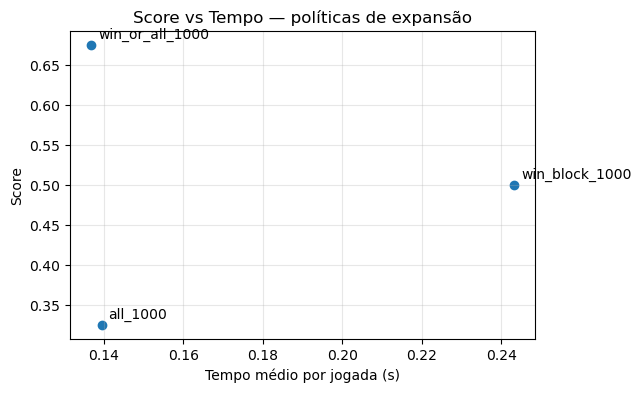

In [19]:
plot_bars(stats_expansion, "Políticas de expansão (1000 iterações)")
plot_score_vs_time(stats_expansion, "Score vs Tempo — políticas de expansão")

#### Discussão dos resultados

Os resultados mostram que a política `get_win_or_all` teve o melhor desempenho, com 27 vitórias em 40 jogos. Isto indica que dar prioridade a jogadas vencedoras imediatas durante a expansão pode melhorar a qualidade da pesquisa, sem alterar demasiado o custo temporal em relação à variante base.

A variante `all_1000`, que expande todos os movimentos válidos, obteve apenas 13 vitórias. Isto sugere que, mesmo com 1000 iterações, o MCTS pode desperdiçar parte do orçamento de pesquisa em ramos menos relevantes.

A política `get_win_block_or_all` ficou num resultado intermédio, com 20 vitórias e 20 derrotas. Apesar de tentar evitar jogadas que permitem vitória imediata ao adversário, esta verificação tem um custo maior, aumentando o tempo médio por jogada para cerca de 0.24s. Neste teste, esse custo adicional não se traduziu numa melhoria clara face ao `win_or_all`.

Assim, a melhor estratégia nesta experiência foi `get_win_or_all`, por obter o maior número de vitórias mantendo um tempo médio semelhante ao da variante base.

---
## 4. Minimax com Alpha-Beta Pruning

O Minimax é um algoritmo de pesquisa adversarial **determinístico**. Em vez de estimar o valor de um estado através de simulações aleatórias, explora a árvore de jogo até uma profundidade definida e avalia os estados folha com uma função heurística.

A implementação usa **alpha-beta pruning**, que elimina ramos que já não podem alterar a escolha final, tornando a pesquisa mais eficiente ao evitar avaliações desnecessárias.

### Heurísticas implementadas

As heurísticas são modulares e hierárquicas, cada uma adicionando um componente:

| Heurística | Componentes | Descrição |
|---|---|---|
| `heuristic_win` | — | Retorna ±1 se houver vencedor, 0 caso contrário |
| `heuristic1` | win + threat_3 | Bonifica ameaças de 3 peças consecutivas |
| `heuristic2` | win + threat_3 + center | Acrescenta controlo do centro |
| `heuristic3` | win + next_move_win + threat_3 + center | Deteta também possíveis vitórias no próximo movimento |

Todos os valores são limitados ao intervalo `[-1, 1]`. Isto permite usar estas heurísticas também no MCTS híbrido, mantendo os valores na mesma escala dos resultados normais das simulações: vitória `1`, empate `0` e derrota `-1`.

### Limitação: fator de ramificação do PopOut

O PopOut tem até **14 movimentos por turno**, comparado com os 7 do Connect-4 clássico. Isto aumenta rapidamente o número de estados que o Minimax teria de analisar quando a profundidade cresce:

- Profundidade 3: cerca de `14³ = 2744` nós;
- Profundidade 4: cerca de `14⁴ = 38416` nós;
- Profundidade 5: cerca de `14⁵ = 537824` nós.

Mesmo com **alpha-beta pruning**, o custo cresce de forma exponencial. Por isso, profundidades mais altas tornam-se demasiado pesadas para usar em tempo real, sobretudo ao jogar contra contra um humano.

### Experiência 6 — Impacto da heurística

O objetivo desta experiência é isolar e medir o impacto das diferentes funções de avaliação nas decisões do algoritmo. Para garantir uma comparação justa, a profundidade de pesquisa foi fixada no nível 3 para todas as três heurísticas compostas.

In [20]:
minimax_heuristic_variants = [
    ("minimax_h1_d3", Minimax(max_depth=3, heuristic=heuristic1, pruning=True)),
    ("minimax_h2_d3", Minimax(max_depth=3, heuristic=heuristic2, pruning=True)),
    ("minimax_h3_d3", Minimax(max_depth=3, heuristic=heuristic3, pruning=True)),
]

stats_minimax_h = variants_stats(minimax_heuristic_variants, n_games=10)
stats_dataframe(stats_minimax_h)

,wins,draws,losses,total_games,win_rate,draw_rate,loss_rate,score,avg_time_per_move
minimax_h3_d3,30,0,10,40,0.75,0.0,0.25,0.75,0.132528
minimax_h2_d3,20,0,20,40,0.50,0.0,0.50,0.50,0.048803
minimax_h1_d3,10,0,30,40,0.25,0.0,0.75,0.25,0.026323


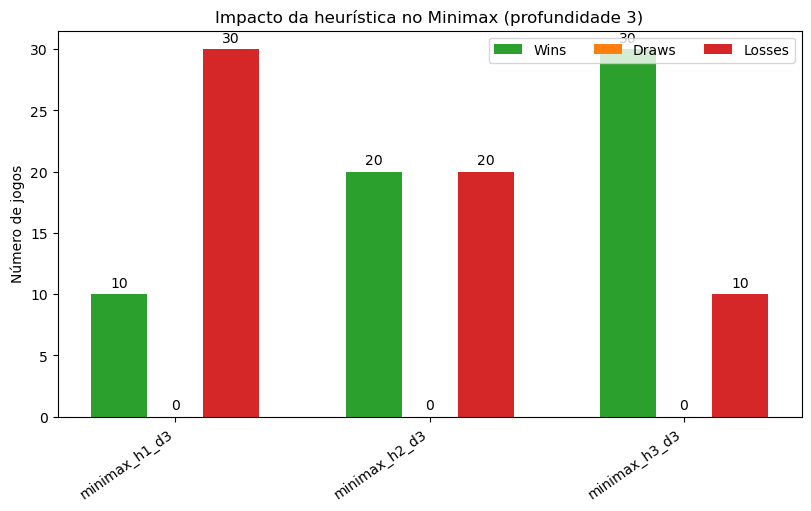

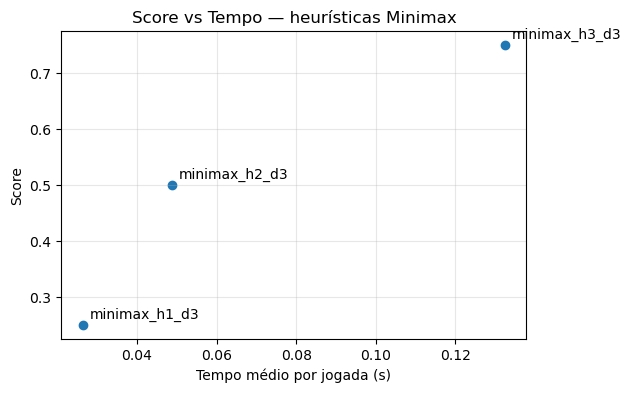

In [21]:
plot_bars(stats_minimax_h, "Impacto da heurística no Minimax (profundidade 3)")
plot_score_vs_time(stats_minimax_h, "Score vs Tempo — heurísticas Minimax")

A tabela mostra apenas resultados agregados, por isso não dá para ver diretamente contra que variante cada heurística ganhou ou perdeu. Ainda assim, o aumento regular de 10 vitórias entre `minimax_h1_d3`, `minimax_h2_d3` e `minimax_h3_d3` sugere que cada nova heurística melhora o resultado global.

No entanto, este padrão também pode estar influenciado pela ordem em que as variantes jogam, já que jogar em primeiro lugar parece dar alguma vantagem. Para verificar esse efeito, foi feito um teste direto entre `minimax_h2_d3` e `minimax_h3_d3` nas duas ordens de jogo.

In [ ]:
#heuristic 2 (h2) plays first
stat1 = Game("","").notebook_run(
    "minimax_h2_d3", Minimax(max_depth=3, heuristic=heuristic2, pruning=True).move,
    "minimax_h3_d3", Minimax(max_depth=3, heuristic=heuristic3, pruning=True).move
)
#heuristic 3 (h3) plays first
stat2 = Game("","").notebook_run(
    "minimax_h3_d3", Minimax(max_depth=3, heuristic=heuristic3, pruning=True).move,
    "minimax_h2_d3", Minimax(max_depth=3, heuristic=heuristic2, pruning=True).move
)
print(stat1["winner_name"])
print(stat2["winner_name"])

minimax_h2_d3
minimax_h3_d3


#### Discussão dos resultados

Os resultados mostram uma melhoria progressiva com a evolução das heurísticas: `minimax_h1_d3` obtém 10 vitórias, `minimax_h2_d3` sobe para 20 e `minimax_h3_d3` atinge 30 vitórias em 40 jogos.

A adição do controlo do centro em `heuristic2` melhora o resultado face a `heuristic1`. Já `heuristic3`, ao acrescentar a deteção de possíveis vitórias no próximo movimento, apresenta o melhor desempenho global.

No entanto, o teste direto entre `minimax_h2_d3` e `minimax_h3_d3` mostra que a ordem de jogo também influencia os resultados: cada variante venceu quando jogou em primeiro lugar. Assim, `heuristic3` é a melhor nos resultados agregados, mas não vence necessariamente todos os confrontos diretos em qualquer ordem.

Em termos de tempo, `minimax_h3_d3` é a variante mais lenta, com cerca de 0.13s por jogada. Ainda assim, continua a ser um valor aceitável para jogar contra uma pessoa.

Assim, para profundidade 3, `heuristic3` apresenta o melhor compromisso geral entre qualidade das decisões e tempo de resposta.

### Experiência 7 — Impacto da profundidade

Esta experiência compara o `Minimax`, usando a heurística mais completa testada (`heuristic3`), com uma referência do `MoveMCTS`.

O objetivo é perceber se aumentar a profundidade do `Minimax` melhora a qualidade das decisões, e se esse ganho compensa o aumento do tempo médio por jogada.

Foram testadas duas configurações:

- **`minimax_h3_d3`**: profundidade 3, usada como referência por ser rápida.
- **`minimax_h3_d4`**: profundidade 4, para testar o impacto de analisar mais um nível da árvore.
- **`mcts_ref_1000`**: referência baseada em `MoveMCTS`, com 1000 iterações e a política de expansão `get_win_block_or_all`.

Como o PopOut pode ter até 14 movimentos possíveis por turno, aumentar a profundidade no `Minimax` aumenta rapidamente o número de estados analisados. Assim, esta experiência avalia o compromisso entre profundidade, qualidade das decisões e tempo de execução.

In [22]:
# Referência MCTS para comparação
mcts_ref = MoveMCTS(max_iter=1000, expansion_policy=get_win_block_or_all)

minimax_depth_variants = [
    ("minimax_h3_d3", Minimax(max_depth=3, heuristic=heuristic3, pruning=True)),
    ("minimax_h3_d4", Minimax(max_depth=4, heuristic=heuristic3, pruning=True)),
    ("mcts_ref_1000", mcts_ref),
]

stats_depth = variants_stats(minimax_depth_variants, n_games=10)
stats_dataframe(stats_depth)

,wins,draws,losses,total_games,win_rate,draw_rate,loss_rate,score,avg_time_per_move
mcts_ref_1000,29,0,11,40,0.725,0.0,0.275,0.725,0.249572
minimax_h3_d4,29,0,11,40,0.725,0.0,0.275,0.725,0.513838
minimax_h3_d3,2,0,38,40,0.050,0.0,0.950,0.050,0.129572


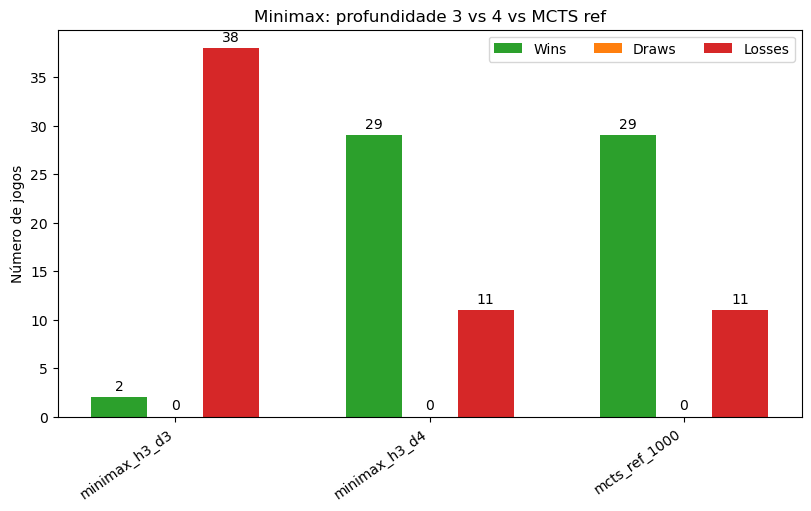

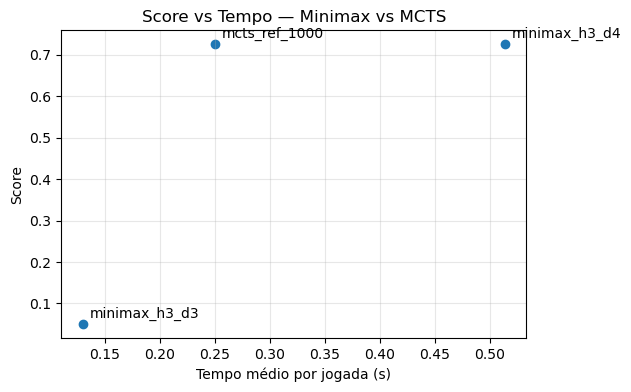

In [23]:
plot_bars(stats_depth, "Minimax: profundidade 3 vs 4 vs MCTS ref")
plot_score_vs_time(stats_depth, "Score vs Tempo — Minimax vs MCTS")

#### Discussão dos resultados

Os resultados mostram que aumentar a profundidade do `Minimax` teve um impacto muito forte. A variante `minimax_h3_d3` obteve apenas 2 vitórias em 40 jogos, enquanto `minimax_h3_d4` subiu para 29 vitórias, igualando o resultado de `mcts_ref_1000`.

Isto indica que, para esta heurística, a profundidade 3 é demasiado limitada para avaliar bem as posições. Com profundidade 4, o `Minimax` passa a antecipar melhor as consequências das jogadas e torna-se competitivo com o `MoveMCTS`.

No entanto, este ganho tem um custo temporal. O tempo médio por jogada aumenta de cerca de 0.13s em `minimax_h3_d3` para cerca de 0.51s em `minimax_h3_d4`. O `MoveMCTS` obtém o mesmo número de vitórias que `minimax_h3_d4`, mas com um tempo médio inferior, cerca de 0.25s por jogada.

Assim, a profundidade 4 melhora muito a qualidade do `Minimax`, mas também torna a pesquisa bastante mais pesada. Neste teste, `minimax_h3_d4` e `mcts_ref_1000` têm o mesmo desempenho em vitórias, mas o `MoveMCTS` apresenta melhor relação entre resultado e tempo de execução.

---
## 5. MCTS híbrido — Minimax como avaliador do rollout

Nesta experiência, o rollout aleatório do `MoveMCTS` é substituído por uma avaliação com `Minimax`. Em vez de simular jogadas aleatórias até ao fim da partida, cada nó expandido é avaliado com uma pesquisa determinística de profundidade limitada.

A ideia é tornar cada avaliação mais informativa, usando a `heuristic3` já testada anteriormente. No entanto, esta alteração aumenta bastante o custo de cada iteração, porque cada avaliação passa a executar uma pesquisa Minimax. Por isso, as variantes híbridas usam apenas 100 iterações, sendo comparadas com o `MoveMCTS` puro com 1000 iterações.

Também são testadas duas formas de propagar o valor devolvido pelo Minimax:

- `normalize_minimax=True`: o valor devolvido pelo Minimax é convertido apenas para `-1`, `0` ou `1`, conforme indique derrota, empate ou vitória;
- `normalize_minimax=False`: o valor original da heurística é propagado diretamente, mantendo valores intermédios dentro da mesma escala `[-1, 1]`.

### Experiência 8 — Normalização vs valor direto na retropropagação


In [24]:
minimax_eval = Minimax(max_depth=3, heuristic=heuristic3, pruning=True)

hybrid_variants = [
    ("hybrid_norm_100", MoveMCTS(
        max_iter=100,
        expansion_policy=get_win_block_or_all,
        use_minimax=True,
        minimax_agent=minimax_eval,
        normalize_minimax=True,
    )),
    ("hybrid_raw_100", MoveMCTS(
        max_iter=100,
        expansion_policy=get_win_block_or_all,
        use_minimax=True,
        minimax_agent=minimax_eval,
        normalize_minimax=False,
    )),
    ("mcts_pure_1000", MoveMCTS(max_iter=1000, expansion_policy=get_win_block_or_all)),
]

stats_hybrid = variants_stats(hybrid_variants, n_games=10)
stats_dataframe(stats_hybrid)

,wins,draws,losses,total_games,win_rate,draw_rate,loss_rate,score,avg_time_per_move
mcts_pure_1000,40,0,0,40,1.000,0.000,0.000,1.0000,0.234674
hybrid_raw_100,9,9,22,40,0.225,0.225,0.550,0.3375,1.564969
hybrid_norm_100,2,9,29,40,0.050,0.225,0.725,0.1625,1.576556


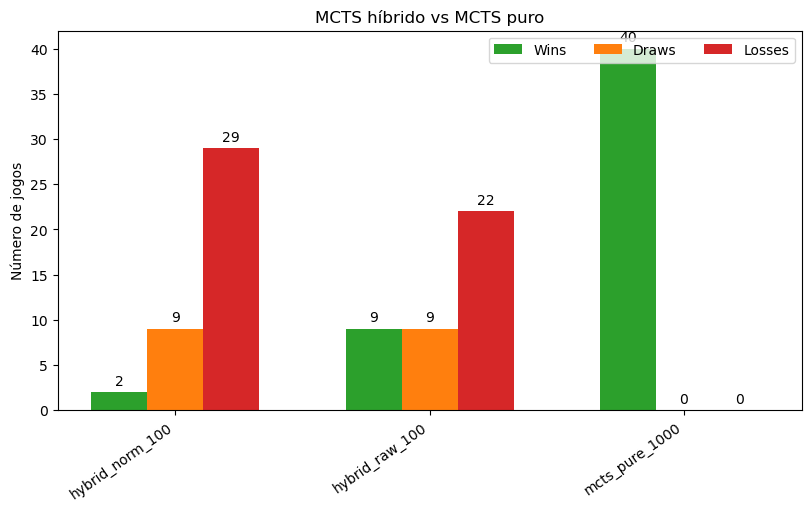

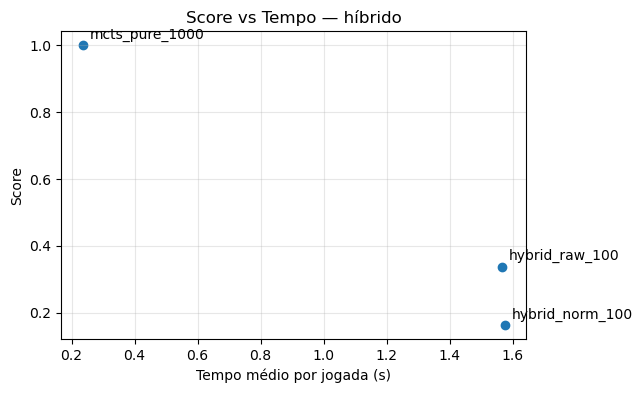

In [ ]:
plot_bars(stats_hybrid, "MCTS híbrido vs MCTS puro")
plot_score_vs_time(stats_hybrid, "Score vs Tempo — híbrido")

#### Discussão dos resultados

Os resultados mostram que o `MoveMCTS` puro com 1000 iterações foi claramente superior às variantes híbridas, vencendo todos os jogos. Isto indica que, nesta configuração, substituir os rollouts por avaliações Minimax não compensou.

As variantes híbridas também foram bastante mais lentas, com tempos médios por jogada próximos de 1.5s, apesar de usarem apenas 100 iterações. Isto acontece porque cada avaliação passa a executar uma pesquisa Minimax, tornando cada iteração muito mais cara.

Entre as duas versões híbridas, `hybrid_raw_100` teve melhor desempenho do que `hybrid_norm_100`, obtendo 9 vitórias contra 2. Isto sugere que manter os valores intermédios da heurística em `[-1, 1]` preserva mais informação do que reduzir a avaliação apenas a `-1`, `0` ou `1`, mesmo alterando a influência da componente de exploitation no UCT

Os empates aparecem apenas nas variantes híbridas, mas não é possível concluir com certeza a sua causa a partir destes resultados. Podem estar relacionados com linhas de jogo que acabam efetivamente em empate segundo as regras implementadas e que o minimax não tem conhecimento.

Assim, nesta implementação, o MCTS híbrido não apresenta uma boa relação entre qualidade e tempo de execução. O custo adicional do Minimax torna a pesquisa demasiado lenta e não melhora os resultados face ao `MoveMCTS` puro.

#### Discussão dos resultados

Os resultados mostram que a deteção de ciclos melhorou o desempenho nesta experiência. A variante `move_cycle_1000` obteve 13 vitórias contra 7 da versão `move_base_1000`.

Em termos de tempo, a diferença entre as duas variantes é muito pequena: ambas ficam perto de 0.45s por jogada. Isto indica que o custo de manter um mapa de estados visitados dentro de cada rollout não teve impacto relevante no tempo médio.

Assim, nesta configuração, a deteção de ciclos parece ser uma melhoria útil: altera apenas a fase de simulação, evita que rollouts repetitivos sejam prolongados desnecessariamente e melhora os resultados sem aumentar significativamente o custo computacional.

## 7. Comparação geral das melhores configurações

Nesta última experiência são comparadas as melhores variantes identificadas ao longo dos testes anteriores, usando `n_games=10` para manter o tempo de execução controlado.

A comparação já não inclui o `MCTS` original baseado em estados, uma vez que a versão `MoveMCTS` mostrou ser muito mais eficiente e passou a ser a base das experiências seguintes.

Além das melhores configurações até aqui vistas, é também incluída a variante com `cycle_detection`. Esta regra adicional é testada para perceber se a deteção de ciclos nos rollouts melhora a configuração final do `MoveMCTS`.

A deteção de ciclos implementada não acompanha o jogo inteiro: usa apenas um dicionário local para cada rollout, reiniciado a cada nova simulação.
Uma versão global teria de guardar o dicionário de estados no `Game` e passá-lo aos métodos `move`, o que exigiria alterar os seus argumentos a todos os algoritmos, porque, atualmente, recebem apenas `board` e `player`.

A opção `max_depth` não é incluída nesta comparação porque exigiria testar diferentes valores de profundidade para escolher um limite adequado. Como a deteção de ciclos já procura controlar rollouts repetitivos de forma automática, foi essa a regra adicional mantida para a comparação final.

As variantes comparadas são:

- `move_cycle_1000`: configuração do `MoveMCTS` com política de expansão `get_win_block_or_all`, política de simulação `heuristic_win`, reutilização da árvore e deteção de ciclos;
- `move_base_1000`: mesma configuração, mas sem deteção de ciclos, servindo como comparação direta para avaliar o impacto dessa regra;
- `minimax_h3_d4`: melhor configuração do `Minimax`, usando `heuristic3` e profundidade 4;
- `hybrid_raw_100`: versão híbrida, que mantém a política de expansão do `MoveMCTS`, mas substitui o rollout aleatório por uma avaliação `Minimax`.

A política de simulação `heuristic_win` é usada nas variantes finais do `MoveMCTS` porque, nas experiências anteriores, melhorou o desempenho e também reduziu o tempo médio por jogada.

O objetivo é comparar as abordagens mais fortes e verificar, dentro da própria comparação final, se a deteção de ciclos traz vantagem à melhor configuração do `MoveMCTS`.

In [4]:
final_variants = [
    # Melhor MoveMCTS com deteção de ciclos, política de simulação e reutilização da árvore
    ("move_cycle_1000", MoveMCTS(
        max_iter=1000,
        expansion_policy=get_win_block_or_all,
        heuristic_win=True,
        save_tree=True,
        cycle_detection=True
    )),

    # Mesma configuração, mas sem deteção de ciclos
    ("move_base_1000", MoveMCTS(
        max_iter=1000,
        expansion_policy=get_win_block_or_all,
        heuristic_win=True,
        save_tree=True
    )),

    # Melhor Minimax
    ("minimax_h3_d4", Minimax(
        max_depth=4,
        heuristic=heuristic3,
        pruning=True
    )),

    # Melhor variante híbrida com politica de expnasao
    ("hybrid_raw_100", MoveMCTS(
        max_iter=100,
        expansion_policy=get_win_block_or_all,
        use_minimax=True,
        minimax_agent=Minimax(max_depth=3, heuristic=heuristic3, pruning=True),
        normalize_minimax=False,
    )),
]

stats_final = variants_stats(final_variants, n_games=10)
stats_dataframe(stats_final)

,wins,draws,losses,total_games,win_rate,draw_rate,loss_rate,score,avg_time_per_move
move_base_1000,50,0,10,60,0.833333,0.0,0.166667,0.833333,0.427036
move_cycle_1000,45,0,15,60,0.750000,0.0,0.250000,0.750000,0.447279
minimax_h3_d4,25,0,35,60,0.416667,0.0,0.583333,0.416667,0.422977
hybrid_raw_100,0,0,60,60,0.000000,0.0,1.000000,0.000000,1.254694


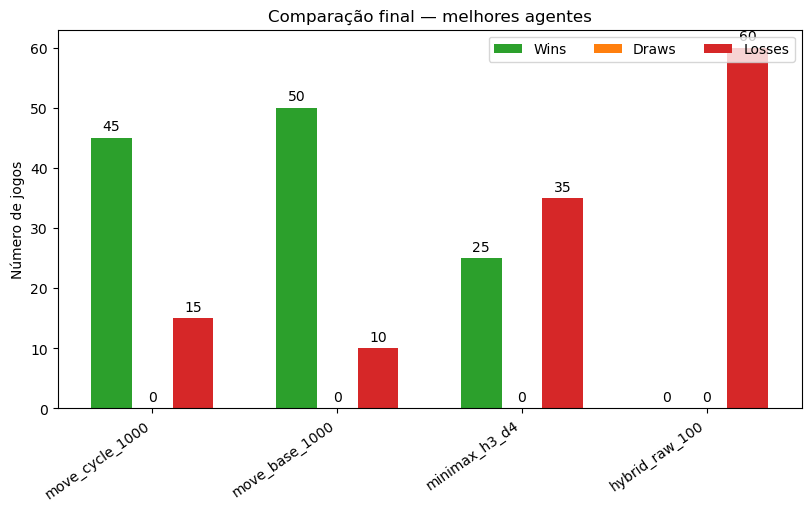

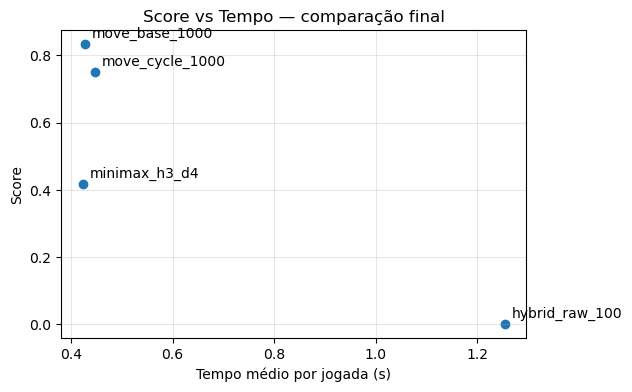

In [5]:
plot_bars(stats_final, "Comparação final — melhores agentes")
plot_score_vs_time(stats_final, "Score vs Tempo — comparação final")

#### Discussão dos resultados

Na comparação final, a melhor variante foi `move_base_1000`, com 50 vitórias em 60 jogos e score de 0.83. Esta configuração junta a versão baseada em movimentos, a política de expansão `get_win_block_or_all`, a política de simulação `heuristic_win` e a reutilização da árvore.

A variante com deteção de ciclos, `move_cycle_1000`, ficou muito próxima, com 45 vitórias e score de 0.75. A diferença não é muito grande e pode estar associada à aleatoriedade das simulações, mas neste teste a regra de ciclos revelou-se ligeiramente pior do que a versão base. Assim, a deteção de ciclos não parece trazer uma melhoria clara nesta configuração.

O `minimax_h3_d4` teve um resultado intermédio, com 25 vitórias. Apesar de ser competitivo, ficou abaixo das variantes de `MoveMCTS`, reforçando que, para este problema, o MCTS baseado em movimentos teve melhor equilíbrio entre desempenho e tempo.

A variante híbrida `hybrid_raw_100` teve o pior resultado, perdendo todos os jogos. Além disso, foi a mais lenta, com cerca de 1.25s por jogada, confirmando que substituir o rollout por uma avaliação Minimax não compensou nesta implementação e com as heurísticas criadas.

Assim, para o jogo contra humano, a melhor opção será `move_base_1000`. Para confrontos automáticos `MCTS` vs `MCTS`, também faz sentido usar esta configuração como referência principal, podendo comparar com `move_cycle_1000` apenas como variante experimental.

---
## 7. Limitações, melhorias futuras e conclusão

### Limitações

- **Aleatoriedade**: o MCTS é estocástico. Diferentes execuções podem produzir resultados diferentes, especialmente com amostras pequenas. Os resultados devem ser interpretados como tendências, não como prova estatística forte.
- **Tamanho das amostras**: o número de jogos por par é limitado pelo tempo de execução. Amostras de 10-20 jogos têm variância elevada — diferenças de score inferiores a 0.05 são pouco fiáveis.
- **Custo do `block`**: a heurística `block` e a política `get_win_block_or_all` aumentam muito o custo por iteração porque avaliam as respostas do adversário. O impacto no tempo deve sempre ser considerado.
- **Heurísticas do Minimax**: as heurísticas implementadas são baseadas em conhecimento geral do Connect-4. Heurísticas específicas para PopOut (que consideram o efeito dos pops) poderiam melhorar o Minimax de forma significativa.
- **Factor de ramificação**: o PopOut tem até 14 movimentos por turno, o que limita severamente a profundidade prática do Minimax. O alpha-beta pruning ajuda, mas a qualidade da ordenação dos nós afecta muito a eficácia da poda — e nesta implementação os nós não são ordenados por valor estimado antes de explorar.

### Melhorias Futuras

### Conclusão
- o que se usa durante a simulação não é bem uma heuristica como as que tou a criar agora -> usar palavras diferentes?- usar simulation_policies como se fez para a expansao
- mcts original em players.py e o novo mcts melhor está em mcts_moves.py -> melhorar a organização?
- limpar alguns comentários e melhorar a escrita?
- para a regra adicional de ciclos, nós implementamos um mapa ao nivel da simulacao e cada vez que comeca uma nova simulacao
    esse mapa volta a comecar vazio e nao pega no mapa do jogo inteiro, seria uma possivel melhoria mas ... nao estou a ver uma maneira simples e rapida de fazer isso, temos que mudar os metodos .move todos acho eu
    mas esta regra nao influencia muito a capacidade do mcts jogar bem, pelo menos só faz com que achasse que iria continuar a jogar na vdd empatou(o que ate agora nao esta a acontecer nas analises)
-as ias/agentes quando estao a jogar se uma das regras adicionais de possibilidade de empatar acontecer, elas escolhem logo empatar
(notas sobre nuances/assumpções que fizemos)

Uma melhoria possível seria ordenar os movimentos antes da pesquisa Minimax, testando primeiro jogadas mais promissoras. Isto poderia tornar o alpha-beta pruning mais eficaz, porque bons cortes dependem bastante da ordem em que os ramos são explorados.
possivel melhoria nas fucnoes que se criou para ver mais detalhes nas estatisticas, ao agregar os dados dos jogos perde-se a informacao dos players e se jogavam em primeiro ou em segundo
comparar os 